In [37]:
# Supress Warnings 
import warnings
warnings.filterwarnings('ignore')


# Import common GIS tools
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import rioxarray as rio
import rasterio
from matplotlib.cm import RdYlGn,jet,RdBu

# Import Planetary Computer tools
import stackstac
import pystac_client
import planetary_computer 
from odc.stac import stac_load

In [38]:
# Define the bounding box for the entire data region using (Latitude, Longitude)
# This is the region of New York City that contains our temperature dataset
lower_left = (40.75, -74.01)
upper_right = (40.88, -73.86)

# Calculate the bounds for doing an archive data search
# bounds = (min_lon, min_lat, max_lon, max_lat)
bounds = (lower_left[1], lower_left[0], upper_right[1], upper_right[0])

# Define the time window
time_window = "2021-06-01/2021-09-01"

Using the `pystac_client` we can search the Planetary Computer's STAC endpoint for items matching our query parameters. We will use a period of 3 months as a representative dataset for the region. The query searches for "low cloud" scenes with overall cloud cover <30%. The result is the number of scenes matching our search criteria that touch our area of interest. Some of these may be partial scenes or contain clouds.

In [39]:
stac = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

search = stac.search(
    bbox=bounds, 
    datetime=time_window,
    collections=["sentinel-2-l2a"],
    query={"eo:cloud_cover": {"lt": 30}},
)

items = list(search.get_items())
print('This is the number of scenes that touch our region:',len(items))

This is the number of scenes that touch our region: 10


In [40]:
signed_items = [planetary_computer.sign(item).to_dict() for item in items]

# Define the pixel resolution for the final product
# Define the scale according to our selected crs, so we will use degrees
resolution = 10  # meters per pixel 
scale = resolution / 111320.0 # degrees per pixel for crs=4326 

#!pip install "dask[diagnostics]" --upgrade
#!pip install jinja2

import dask, jinja2


In [41]:
data = stac_load(
    items,
    bands=["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"],
    crs="EPSG:4326", # Latitude-Longitude
    resolution=scale, # Degrees
    chunks={"x": 2048, "y": 2048},
    dtype="uint16",
    patch_url=planetary_computer.sign,
    bbox=bounds
)



In [42]:
display(data)

<xarray.Dataset>
Dimensions:      (latitude: 1448, longitude: 1671, time: 10)
Coordinates:
  * latitude     (latitude) float64 40.88 40.88 40.88 ... 40.75 40.75 40.75
  * longitude    (longitude) float64 -74.01 -74.01 -74.01 ... -73.86 -73.86
    spatial_ref  int32 4326
  * time         (time) datetime64[ns] 2021-06-06T15:38:09.024000 ... 2021-08...
Data variables:
    B01          (time, latitude, longitude) uint16 dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B02          (time, latitude, longitude) uint16 dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B03          (time, latitude, longitude) uint16 dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B04          (time, latitude, longitude) uint16 dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B05          (time, latitude, longitude) uint16 dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B06          (time, latitude, longitude) uint16 dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B07          (time, latitude, longitude) uint16 dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B08          (time, latitude, longitude) uint16 dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B8A          (time, latitude, longitude) uint16 dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B11          (time, latitude, longitude) uint16 dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B12          (time, latitude, longitude) uint16 dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>

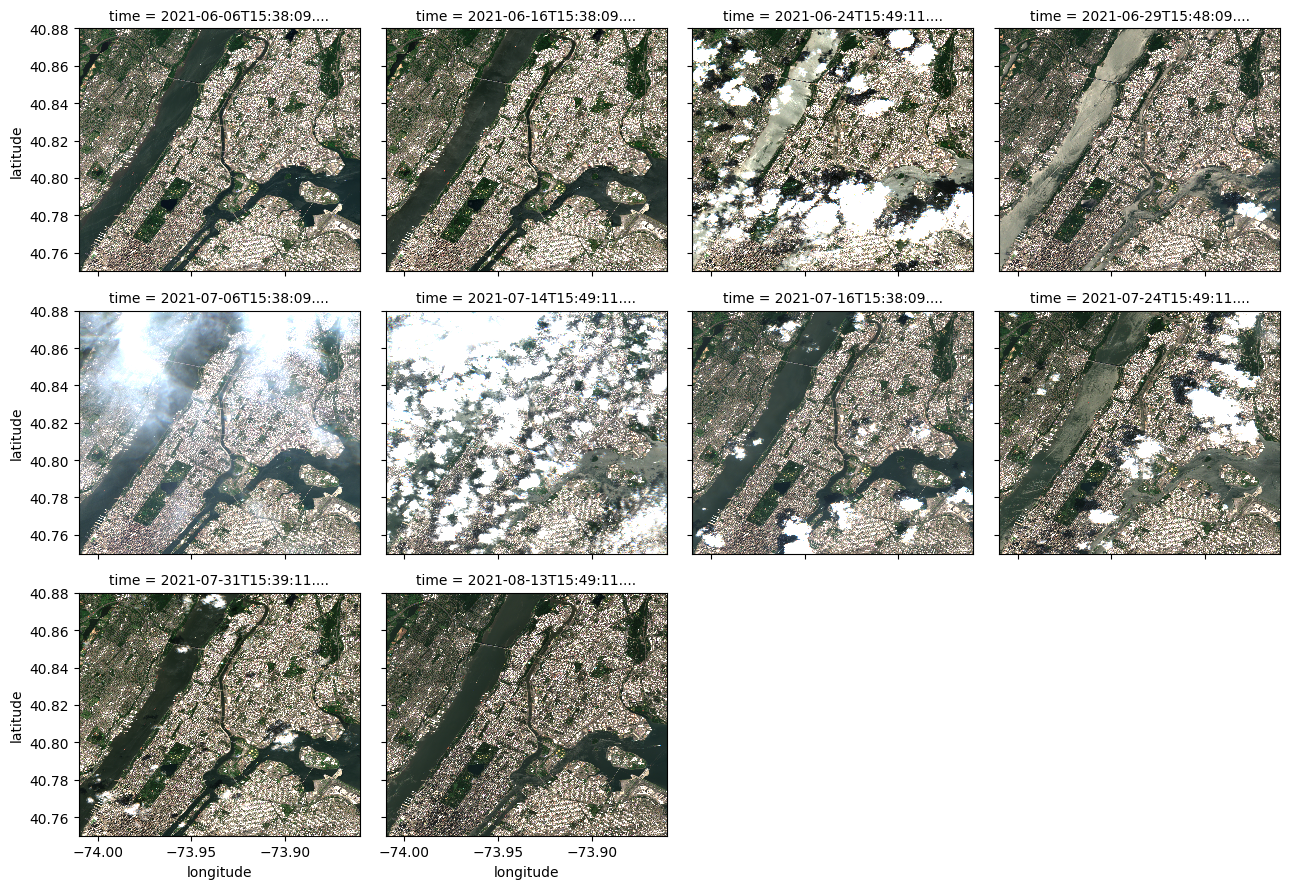

In [13]:
# Plot sample images from the time series
plot_data = data[["B04","B03","B02"]].to_array()
plot_data.plot.imshow(col='time', col_wrap=4, robust=True, vmin=0, vmax=2500)
plt.show()

### Median composite

Using normal xarray operations, we can [compute the median](http://xarray.pydata.org/en/stable/generated/xarray.DataArray.median.html) over the time dimension. Under the assumption that clouds are not common (<30% per scene) and in random locations, the composite shouldn't contain (many) clouds, since they shouldn't be the median pixel value at that point over many images. 

In [43]:
median = data.median(dim="time").compute() #to reduce the impact of clouds.

In [ ]:
# Calculate NDVI for the median mosaic
ndvi_median = (median.B08 - median.B04) / (median.B08 + median.B04)

# Calculate NDBI for the median mosaic
ndbi_median = (median.B11 - median.B08) / (median.B11 + median.B08)

# Calculate NDWI for the median mosaic
ndwi_median = (median.B03 - median.B08) / (median.B03 + median.B08)

median_filename = "median_composite.tiff"
ndvi_filename = "ndvi_median.tiff"
ndbi_filename = "ndbi_median.tiff"
ndwi_filename = "ndwi_median.tiff"


# Define the dimensions and transform
height = median.dims["latitude"]
width = median.dims["longitude"]
gt = rasterio.transform.from_bounds(lower_left[1], lower_left[0], upper_right[1], upper_right[0], width, height)

# Save the median composite
#he median composite is saved as a GeoTIFF file with four bands
with rasterio.open(median_filename, 'w', driver='GTiff', width=width, height=height,
                   crs='epsg:4326', transform=gt, count=4, compress='lzw', dtype='float64') as dst:
    dst.write(median.B01, 1)
    dst.write(median.B04, 2)
    dst.write(median.B06, 3)
    dst.write(median.B08, 4)

In [ ]:
def save_index_as_tiff(index_data, filename, gt, width, height):
    """The calculated indices (NDVI, NDBI, NDWI) are derived from the spectral bands of the median composite. 
    These indices are used to highlight specific features or characteristics of the landscape, such as vegetation health (NDVI),
    built-up areas (NDBI), and water bodies (NDWI).
    Each index is calculated using specific bands from the median composite and is saved as a separate GeoTIFF file with a single band:"""
    
    with rasterio.open(filename, 'w', driver='GTiff', width=width, height=height,
                       crs='epsg:4326', transform=gt, count=1, compress='lzw', dtype='float64') as dst:
        dst.write(index_data.values, 1)

# Save NDVI
save_index_as_tiff(ndvi_median, ndvi_filename, gt, width, height)

# Save NDBI
save_index_as_tiff(ndbi_median, ndbi_filename, gt, width, height)

# Save NDWI
save_index_as_tiff(ndwi_median, ndwi_filename, gt, width, height)

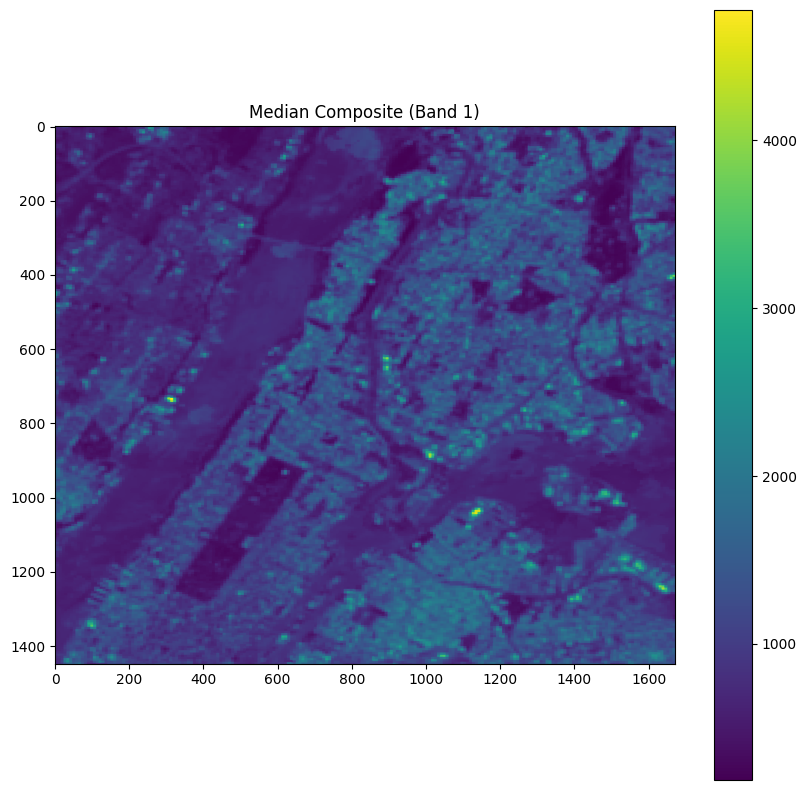

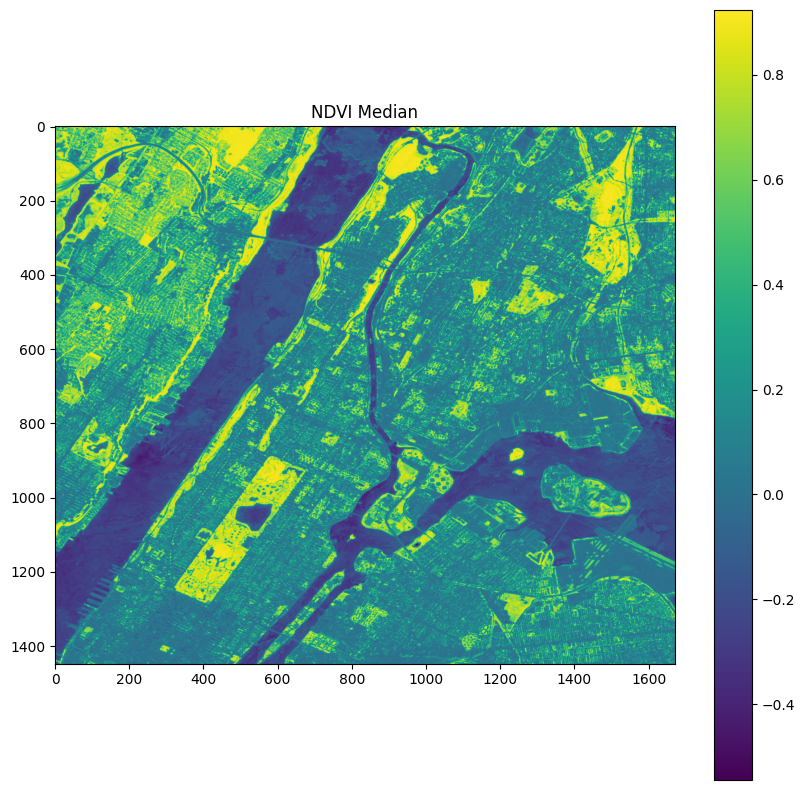

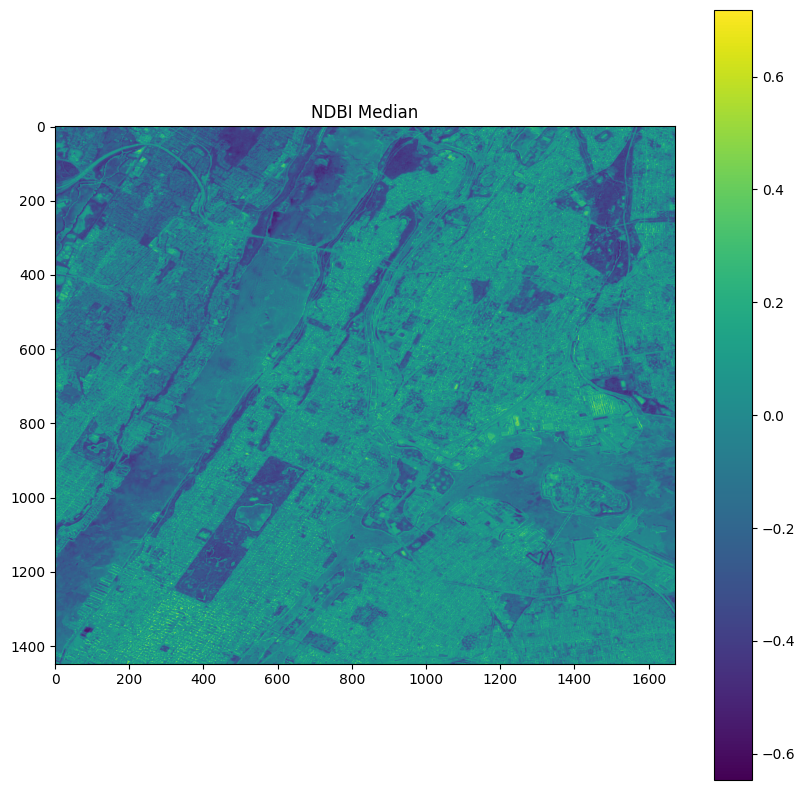

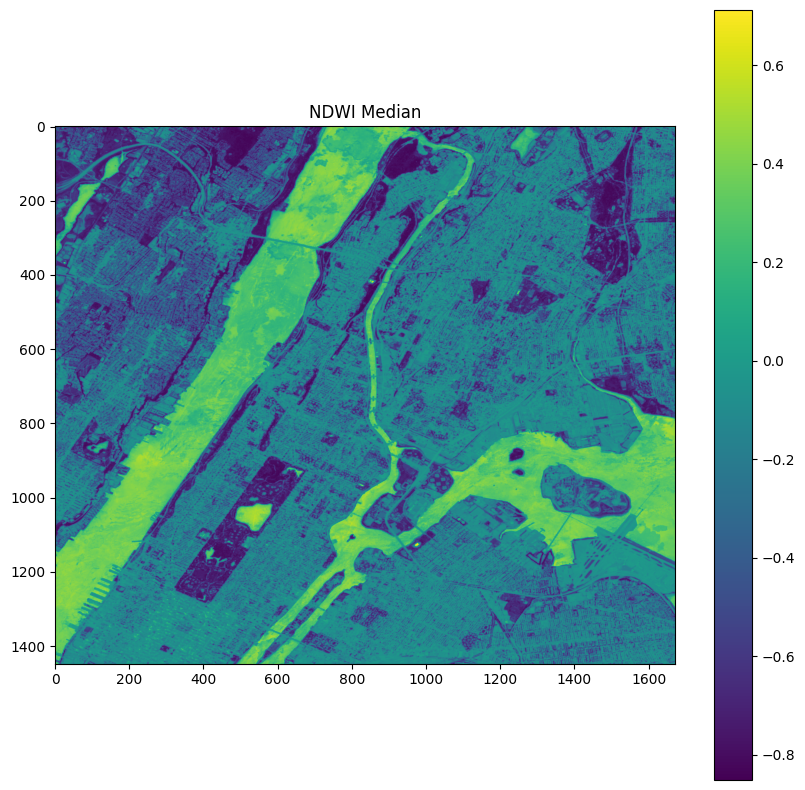

In [ ]:
import matplotlib.pyplot as plt

def plot_geotiff(filename, title):
    with rasterio.open(filename) as src:
        data = src.read(1)
        plt.figure(figsize=(10, 10))
        plt.imshow(data, cmap='viridis')
        plt.title(title)
        plt.colorbar()
        plt.show()

# Plot the median composite (one of the bands)
plot_geotiff("median_composite.tiff", "Median Composite (Band 1)")

# Plot NDVI
plot_geotiff("ndvi_median.tiff", "NDVI Median")

# Plot NDBI
plot_geotiff("ndbi_median.tiff", "NDBI Median")

# Plot NDWI
plot_geotiff("ndwi_median.tiff", "NDWI Median")

In [ ]:
import numpy as np

# Load the median composite
with rasterio.open("median_composite.tiff") as src:
    median_data = src.read()  # This will load all bands

# Load the NDVI index
with rasterio.open("ndvi_median.tiff") as src:
    ndvi_data = src.read(1)  # Load the first (and only) band

# Load the NDBI index
with rasterio.open("ndbi_median.tiff") as src:
    ndbi_data = src.read(1)  # Load the first (and only) band

# Load the NDWI index
with rasterio.open("ndwi_median.tiff") as src:
    ndwi_data = src.read(1)  # Load the first (and only) band

# Combine all data into a single array for the ML model
# Assuming median_data has shape (bands, height, width)
# and ndvi_data, ndbi_data, ndwi_data have shape (height, width)
combined_data = np.vstack([
    median_data,
    ndvi_data[np.newaxis, :, :],  # Add a new axis to match the shape
    ndbi_data[np.newaxis, :, :],  # Add a new axis to match the shape
    ndwi_data[np.newaxis, :, :]   # Add a new axis to match the shape
])

# Now combined_data has shape (bands + 3, height, width)
# use this combined_data as input features for your ML model

For each coordinate, ewe now extracts the corresponding pixel values from the combined data array. If a buffer radius is provided, it calculates the average values within the buffer area around the coordinate.

In [ ]:
import pandas as pd
from pyproj import Proj, Transformer

# Install tqdm if not already installed
%pip install tqdm
from tqdm import tqdm

# Function to map satellite data to geo-locations
def map_satellite_data(combined_data, csv_path, transform, crs, buffer_radius=None):
    # Read the CSV file using pandas
    df = pd.read_csv(csv_path)
    latitudes = df['Latitude'].values
    longitudes = df['Longitude'].values

    # Convert lat/long to the GeoTIFF's CRS
    proj_wgs84 = Proj(init='epsg:4326')  # EPSG:4326 is the common lat/long CRS
    proj_tiff = Proj(crs)
    transformer = Transformer.from_proj(proj_wgs84, proj_tiff)

    band_values = {f'Band_{i+1}': [] for i in range(combined_data.shape[0])}

    # Iterate over the latitudes and longitudes, and extract the corresponding band values
    for lat, lon in tqdm(zip(latitudes, longitudes), total=len(latitudes), desc="Mapping values"):
        x, y = transformer.transform(lat, lon)
        row, col = ~transform * (x, y)  # Transform to row, col in the array

        if buffer_radius:
            # Create a buffer around the location and calculate the average values within the buffer
            row_min = max(int(row - buffer_radius), 0)
            row_max = min(int(row + buffer_radius), combined_data.shape[1])
            col_min = max(int(col - buffer_radius), 0)
            col_max = min(int(col + buffer_radius), combined_data.shape[2])
            for i in range(combined_data.shape[0]):
                band_value = combined_data[i, row_min:row_max, col_min:col_max].mean()
                band_values[f'Band_{i+1}'].append(band_value)
        else:
            # Extract the nearest pixel value
            row = int(row)
            col = int(col)
            for i in range(combined_data.shape[0]):
                band_value = combined_data[i, row, col]
                band_values[f'Band_{i+1}'].append(band_value)

    # Create a DataFrame with the band values
    df = pd.DataFrame(band_values)

    return df

# Get the transform and CRS from one of the original GeoTIFF files
with rasterio.open("median_composite.tiff") as src:
    transform = src.transform
    crs = src.crs

# Mapping satellite data with training data
final_data = map_satellite_data(combined_data, 'Training_data_uhi_index.csv', transform, crs, buffer_radius=50)

# Display the final data
print(final_data.head())

Note: you may need to restart the kernel to use updated packages.


Mapping values: 100%|██████████| 11229/11229 [00:01<00:00, 8782.08it/s]

     Band_1      Band_2      Band_3      Band_4    Band_5    Band_6    Band_7
0  939.8772  1029.12970  1303.73060  1357.58070  0.008154 -0.021795  0.033941
1  939.8772  1029.12970  1303.73060  1357.58070  0.008154 -0.021795  0.033941
2  935.2600  1021.37825  1288.56490  1339.24765  0.003186 -0.022114  0.040095
3  929.0405  1011.16695  1274.38255  1323.96260 -0.000051 -0.023500  0.044604
4  922.8210  1000.71610  1260.12010  1309.36430 -0.003089 -0.025139  0.048920


In [35]:
final_data.to_csv("combined_data.csv", index=False)